# 05 - Experiment design when you cannot randomise cleanly

A retention team needs two numbers before it runs anything:

1. **How many customers?** - power, sample size, and the design effect from
   randomising by area rather than by customer.
2. **What if randomisation is impossible?** - difference-in-differences, with the
   identifying assumption stated and tested.

Design is where the previous notebooks cash out: if a 5 percentage-point effect is
commercially meaningful, this is what it costs to detect it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path
from scipy.optimize import brentq
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

from telco_churn.data import load_clean
from telco_churn.features import make_preprocessor, split_xy
from telco_churn.model import build_pipeline

FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

df = load_clean()
X, y = split_xy(df)
risk = build_pipeline("logistic", seed=42).fit(X, y).predict_proba(X)[:, 1]
top = df.loc[risk >= np.quantile(risk, 0.8)]
p0 = float(top.Churn.mean())

print(f"Target group = top 20% by modelled risk ({len(top):,} customers).")
print(f"Observed churn rate in that group: {p0:.1%}")

Target group = top 20% by modelled risk (1,409 customers).
Observed churn rate in that group: 63.4%


The risk score here is fitted on the same rows it is evaluated on, which is fine
for choosing a *design* baseline but would be optimistic as a performance claim.
Notebook 02 does the held-out evaluation.

## 1. Sample size for a retention offer

The question is the smallest reduction worth detecting, not the smallest the model
can predict. Three candidate effects are shown; 5 pp is the running example.

In [2]:
rows = []
power = NormalIndPower()
for lift in (0.03, 0.05, 0.08):
    es = proportion_effectsize(p0, p0 - lift)
    n = power.solve_power(es, alpha=0.05, power=0.8, ratio=1.0)
    rows.append({"churn reduction (pp)": lift * 100, "customers per arm": int(np.ceil(n))})
sample_sizes = pd.DataFrame(rows)
sample_sizes

,churn reduction (pp),customers per arm
0,3.0,4113
1,5.0,1494
2,8.0,591


In [3]:
# Check the formula by simulation: how often does a two-proportion test detect
# a 5pp reduction at the sample size the formula recommends?
rng = np.random.default_rng(1)
lift = 0.05
n_arm = int(sample_sizes.loc[1, "customers per arm"])
hits, sims = 0, 2000
for _ in range(sims):
    c = rng.binomial(1, p0, n_arm).sum()
    t = rng.binomial(1, p0 - lift, n_arm).sum()
    hits += proportions_ztest([c, t], [n_arm, n_arm])[1] < 0.05
print(f"Simulated power with {n_arm:,} per arm and a {lift*100:.0f}pp reduction: {hits/sims:.1%}")

Simulated power with 1,494 per arm and a 5pp reduction: 78.7%


### The minimum detectable effect at a fixed budget

Sample size answers "how many for this effect". Budget-holders ask the reverse:
"with 1,000 per arm, what is the smallest effect we could see?" The curve below
answers that, and makes the cost of a smaller target explicit.

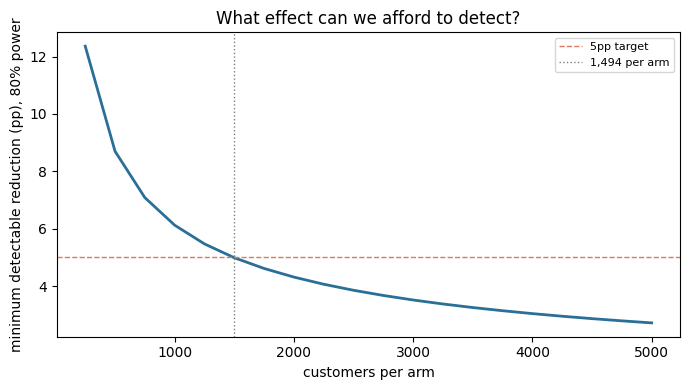

  500 per arm -> can detect a 8.7pp reduction
1,000 per arm -> can detect a 6.1pp reduction


2,000 per arm -> can detect a 4.3pp reduction


In [4]:
def detectable_lift(p0: float, n: int, alpha: float = 0.05, power: float = 0.8) -> float:
    f = lambda delta: (NormalIndPower().solve_power(
        proportion_effectsize(p0, p0 - delta), alpha=alpha, power=power, ratio=1.0) - n)
    return brentq(f, 1e-4, p0 - 1e-4) * 100

ns = np.arange(250, 5001, 250)
mde = [detectable_lift(p0, int(n)) for n in ns]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, mde, color="#2a6f97", lw=2)
ax.axhline(5, color="#e07a5f", ls="--", lw=1, label="5pp target")
ax.axvline(n_arm, color="grey", ls=":", lw=1, label=f"{n_arm:,} per arm")
ax.set_xlabel("customers per arm")
ax.set_ylabel("minimum detectable reduction (pp), 80% power")
ax.set_title("What effect can we afford to detect?")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "05_mde_curve.png", dpi=140)
plt.show()

for n in (500, 1000, 2000):
    print(f"{n:5,} per arm -> can detect a {detectable_lift(p0, n):.1f}pp reduction")

## 2. Clustering: randomising by agent area or region

Field operations often assign whole areas to treatment. Customers in the same
area share agents, local promotions and local conditions, so their outcomes are
correlated. The design effect is `DEFF = 1 + (m - 1) * ICC`, and the required
sample is multiplied by it.

In [5]:
es = proportion_effectsize(p0, p0 - 0.05)
n_ind = NormalIndPower().solve_power(es, alpha=0.05, power=0.8)
rows = []
for icc in (0.01, 0.03, 0.05, 0.10):
    for m in (20, 40, 80):
        deff = 1 + (m - 1) * icc
        rows.append({"ICC": icc, "customers per cluster": m, "design effect": round(deff, 2),
                     "customers per arm": int(np.ceil(n_ind * deff)),
                     "clusters per arm": int(np.ceil(n_ind * deff / m))})
cluster_table = pd.DataFrame(rows)
print(f"Individual-randomisation requirement: {int(np.ceil(n_ind)):,} per arm")
cluster_table.head(8)

Individual-randomisation requirement: 1,494 per arm


,ICC,customers per cluster,design effect,customers per arm,clusters per arm
0,0.01,20,1.19,1778,89
1,0.01,40,1.39,2077,52
2,0.01,80,1.79,2675,34
3,0.03,20,1.57,2346,118
4,0.03,40,2.17,3242,82
5,0.03,80,3.37,5035,63
6,0.05,20,1.95,2914,146
7,0.05,40,2.95,4408,111


The ICC is the number to argue about. It is not estimable from a single snapshot of
one business unless you have area identifiers, so the table should be read as
"here is what changes if the ICC is 0.03 rather than 0.01", not as a recommendation.

## 3. When randomisation is impossible: difference-in-differences

Simulated example: 20 regions, 10 treated from period 3. Treated regions already
had higher churn before the promotion, so the naive post-period comparison is
biased. Difference-in-differences removes the stable gap, assuming the groups
would have followed parallel trends without treatment.

The regression version below includes region and period fixed effects and clusters
standard errors by region, which is the version that would actually be run.

In [6]:
rng = np.random.default_rng(7)
TRUE_EFFECT = -0.04
regions, periods, per_cell = 20, 6, 600
rows = []
for region in range(regions):
    treated = region < 10
    level = 0.22 + (0.06 if treated else 0.0) + rng.normal(0, 0.01)
    for period in range(periods):
        shock = rng.normal(0, 0.012)          # region-period shock creates dependence
        p = level + 0.005 * period + (TRUE_EFFECT if (treated and period >= 3) else 0) + shock
        rows.extend(
            {"region": region, "treated": int(treated), "period": period, "churn": int(v)}
            for v in rng.binomial(1, p, per_cell)
        )
d = pd.DataFrame(rows)
d["post"] = (d.period >= 3).astype(int)

naive = d[(d.post == 1) & (d.treated == 1)].churn.mean() - \
        d[(d.post == 1) & (d.treated == 0)].churn.mean()
twfe = smf.ols("churn ~ treated:post + C(region) + C(period)", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": d.region})
coef = twfe.params["treated:post"]
lo, hi = twfe.conf_int().loc["treated:post"]

print(f"Naive post-period gap: {naive*100:+.1f}pp (biased by the pre-existing level gap)")
print(f"DiD estimate: {coef*100:+.1f}pp, 95% CI [{lo*100:+.1f}, {hi*100:+.1f}] "
      f"(true effect {TRUE_EFFECT*100:+.0f}pp)")
print(f"Clusters: {d.region.nunique()} (few-cluster inference is fragile; note it)")

Naive post-period gap: +3.8pp (biased by the pre-existing level gap)
DiD estimate: -3.9pp, 95% CI [-5.3, -2.6] (true effect -4pp)
Clusters: 20 (few-cluster inference is fragile; note it)


### The identifying assumption, tested where it can be

Parallel trends cannot be proven, but pre-period leads should be near zero. The
event study below replaces the single post indicator with one interaction per
period, omitting the baseline period.

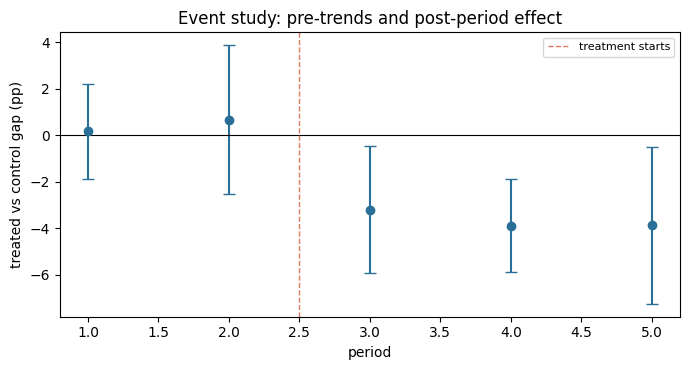

Pre-period leads should straddle zero; post-period coefficients should sit near -4pp.


In [7]:
for t in range(1, periods):
    d[f"treated_x_{t}"] = d.treated * (d.period == t)
terms = " + ".join(f"treated_x_{t}" for t in range(1, periods))
es_model = smf.ols(f"churn ~ {terms} + C(region) + C(period)", data=d).fit(
    cov_type="cluster", cov_kwds={"groups": d.region})

coefs = es_model.params[[f"treated_x_{t}" for t in range(1, periods)]]
cis = es_model.conf_int().loc[coefs.index]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(range(1, periods), coefs * 100,
            yerr=[(coefs - cis[0]) * 100, (cis[1] - coefs) * 100],
            fmt="o", capsize=4, color="#2a6f97")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(2.5, color="#e07a5f", ls="--", lw=1, label="treatment starts")
ax.set_xlabel("period")
ax.set_ylabel("treated vs control gap (pp)")
ax.set_title("Event study: pre-trends and post-period effect")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "05_event_study.png", dpi=140)
plt.show()

print("Pre-period leads should straddle zero; post-period coefficients should sit near -4pp.")

## Takeaways

- Quote sample sizes in **customers and clusters**, and pair them with the minimum
  detectable effect at the budget you actually have.
- Area randomisation is not a detail: an ICC of 0.05 at 40 customers per cluster
  more than doubles the required sample.
- When randomisation is impossible, state the parallel-trends assumption, show
  pre-period leads, include unit and time fixed effects, and cluster the standard
  errors. The naive comparison in the simulation has the wrong sign; the design is
  what makes the estimate credible.
- Do not peek at the result and stop when it looks significant. If the business
  needs continuous monitoring, pre-register an alpha-spending schedule.

## Limitations

- The simulation is illustrative; no real field experiment is used.
- With 20 clusters, cluster-robust inference is itself unreliable. A real study
  should use more clusters or a small-sample correction.
- The churn base rate comes from an in-sample risk ranking. A deployment would
  recompute it on held-out or recent data.